# Week 09：集成学习算法对比实验

## 一、实验目标

1. 理解集成学习（Ensemble Learning）的基本思想。
2. 掌握 Bagging 与 Boosting 两类集成方法的区别。
3. 理解随机森林中的 Bootstrap 和随机特征选择机制。
4. 使用 AdaBoost、Gradient Boosting 和 Stacking 完成分类任务。
5. 对比单个模型与集成模型的分类效果。
6. 使用 Accuracy、Precision、Recall、F1-score 等指标评价模型表现。

## 二、实验环境

- Python 3
- NumPy
- Pandas
- Matplotlib
- Scikit-learn
- Jupyter Notebook

## 三、实验数据集

本实验采用 Scikit-learn 自带的 Breast Cancer Wisconsin 数据集。

该数据集包含 569 个样本、30 个数值特征，目标是根据细胞核特征判断肿瘤属于恶性还是良性。

标签含义：
- 0：malignant（恶性）
- 1：benign（良性）

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
data = load_breast_cancer()

X = data.data
y = data.target

print("特征矩阵形状：", X.shape)
print("标签数组形状：", y.shape)
print("类别名称：", data.target_names)
print("特征数量：", len(data.feature_names))

df = pd.DataFrame(X, columns=data.feature_names)
df["target"] = y

display(df.head())

特征矩阵形状： (569, 30)
标签数组形状： (569,)
类别名称： ['malignant' 'benign']
特征数量： 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [8]:
unique, counts = np.unique(y, return_counts=True)

for label, count in zip(unique, counts):
    ratio = count / len(y) * 100
    print(
        f"类别 {label} ({data.target_names[label]}): "
        f"{count} 个样本，占 {ratio:.2f}%"
    )

print("\n缺失值数量：", df.isnull().sum().sum())
print("重复样本数量：", df.duplicated().sum())

类别 0 (malignant): 212 个样本，占 37.26%
类别 1 (benign): 357 个样本，占 62.74%

缺失值数量： 0
重复样本数量： 0


## 四、数据探索与预处理

数据集包含 569 个样本和 30 个数值特征。

其中：
- 恶性样本：212 个，占 37.26%。
- 良性样本：357 个，占 62.74%。

数据存在一定程度的类别不平衡，因此不能只依赖 Accuracy，
还应关注 Precision、Recall、F1-score 和混淆矩阵。

由于本实验主要使用基于决策树的算法，通常不需要进行特征标准化。

在 Stacking 实验中，如果使用逻辑回归作为基学习器，
则通过 Pipeline 单独进行标准化，避免数据泄漏。

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("训练集：", X_train.shape)
print("测试集：", X_test.shape)

print("\n训练集类别数量：", np.bincount(y_train))
print("测试集类别数量：", np.bincount(y_test))

训练集： (455, 30)
测试集： (114, 30)

训练集类别数量： [170 285]
测试集类别数量： [42 72]


## 五、基准模型：Decision Tree

为了评估集成学习是否能够改善模型性能，
首先使用单棵决策树建立基准模型。

决策树通过不断选择特征与划分阈值完成分类。

本实验先使用一棵不限制最大深度的决策树，
观察其训练表现与测试表现。

后续使用集成学习方法进行对比。

In [10]:
dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

dt_model.fit(X_train, y_train)

dt_train_pred = dt_model.predict(X_train)
dt_test_pred = dt_model.predict(X_test)

print("Decision Tree")
print("Train Accuracy:", accuracy_score(y_train, dt_train_pred))
print("Test Accuracy:", accuracy_score(y_test, dt_test_pred))
print("Tree Depth:", dt_model.get_depth())
print("Leaf Nodes:", dt_model.get_n_leaves())

Decision Tree
Train Accuracy: 1.0
Test Accuracy: 0.9122807017543859
Tree Depth: 7
Leaf Nodes: 19


## 六、Bagging 与随机森林

### 6.1 Bagging

Bagging（Bootstrap Aggregating）的核心思想：

1. 从原始训练集中有放回地抽取样本。
2. 使用不同的 Bootstrap 样本训练多个基学习器。
3. 对分类结果进行投票，得到最终预测。

Bagging 主要通过降低模型方差改善泛化性能。

### 6.2 Random Forest

随机森林在 Bagging 决策树的基础上，
进一步在节点分裂时随机选择部分候选特征。

这种机制可以降低不同决策树之间的相关性，
增强集成模型的多样性。

In [11]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)

bagging_train_pred = bagging_model.predict(X_train)
bagging_test_pred = bagging_model.predict(X_test)

print("Bagging")
print("Train Accuracy:", accuracy_score(y_train, bagging_train_pred))
print("Test Accuracy:", accuracy_score(y_test, bagging_test_pred))
print("OOB Score:", bagging_model.oob_score_)

Bagging
Train Accuracy: 1.0
Test Accuracy: 0.9385964912280702
OOB Score: 0.9560439560439561


In [12]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

print("Random Forest")
print("Train Accuracy:", accuracy_score(y_train, rf_train_pred))
print("Test Accuracy:", accuracy_score(y_test, rf_test_pred))
print("OOB Score:", rf_model.oob_score_)

Random Forest
Train Accuracy: 1.0
Test Accuracy: 0.956140350877193
OOB Score: 0.9538461538461539


In [13]:
bagging_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Bagging",
        "Random Forest"
    ],
    "Train Accuracy": [
        accuracy_score(y_train, dt_train_pred),
        accuracy_score(y_train, bagging_train_pred),
        accuracy_score(y_train, rf_train_pred)
    ],
    "Test Accuracy": [
        accuracy_score(y_test, dt_test_pred),
        accuracy_score(y_test, bagging_test_pred),
        accuracy_score(y_test, rf_test_pred)
    ]
})

display(bagging_comparison.round(4))

,Model,Train Accuracy,Test Accuracy
0,Decision Tree,1.0,0.9123
1,Bagging,1.0,0.9386
2,Random Forest,1.0,0.9561


## 七、Boosting 集成方法

Boosting 与 Bagging 的主要区别在于训练方式。

Bagging：各个基学习器相对独立，可以并行训练。

Boosting：基学习器通常依次训练，后面的模型不断改善
前面模型尚未解决的问题。

本实验使用两种典型方法：

1. AdaBoost：通过调整样本权重，让后续学习器更加关注难分类样本。
2. Gradient Boosting：通过拟合损失函数的负梯度，逐步改进模型预测。

需要注意，Boosting 也可能对噪声和异常值比较敏感。

In [14]:
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=RANDOM_STATE
)

ada_model.fit(X_train, y_train)

ada_train_pred = ada_model.predict(X_train)
ada_test_pred = ada_model.predict(X_test)

print("AdaBoost")
print("Train Accuracy:", accuracy_score(y_train, ada_train_pred))
print("Test Accuracy:", accuracy_score(y_test, ada_test_pred))

AdaBoost
Train Accuracy: 1.0
Test Accuracy: 0.956140350877193


In [15]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)

gb_model.fit(X_train, y_train)

gb_train_pred = gb_model.predict(X_train)
gb_test_pred = gb_model.predict(X_test)

print("Gradient Boosting")
print("Train Accuracy:", accuracy_score(y_train, gb_train_pred))
print("Test Accuracy:", accuracy_score(y_test, gb_test_pred))

Gradient Boosting
Train Accuracy: 1.0
Test Accuracy: 0.956140350877193


In [16]:
boosting_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "AdaBoost",
        "Gradient Boosting"
    ],
    "Train Accuracy": [
        accuracy_score(y_train, dt_train_pred),
        accuracy_score(y_train, ada_train_pred),
        accuracy_score(y_train, gb_train_pred)
    ],
    "Test Accuracy": [
        accuracy_score(y_test, dt_test_pred),
        accuracy_score(y_test, ada_test_pred),
        accuracy_score(y_test, gb_test_pred)
    ]
})

display(boosting_comparison.round(4))

,Model,Train Accuracy,Test Accuracy
0,Decision Tree,1.0,0.9123
1,AdaBoost,1.0,0.9561
2,Gradient Boosting,1.0,0.9561


## 八、Stacking 堆叠集成

Stacking 的核心思想是：

使用多个不同的基学习器进行预测，
然后训练一个额外的元学习器（Meta-learner），
学习如何组合这些预测结果。

本实验选择：

基学习器：
- Decision Tree
- Random Forest
- Logistic Regression

元学习器：
- Logistic Regression

使用交叉验证生成基学习器的折外预测，
减少元学习器训练过程中的数据泄漏。

In [17]:
stacking_model = StackingClassifier(
    estimators=[
        (
            "dt",
            DecisionTreeClassifier(
                max_depth=4,
                random_state=RANDOM_STATE
            )
        ),
        (
            "rf",
            RandomForestClassifier(
                n_estimators=100,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        ),
        (
            "lr",
            make_pipeline(
                StandardScaler(),
                LogisticRegression(max_iter=1000)
            )
        )
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1
)

stacking_model.fit(X_train, y_train)

stacking_train_pred = stacking_model.predict(X_train)
stacking_test_pred = stacking_model.predict(X_test)

print("Stacking")
print("Train Accuracy:", accuracy_score(y_train, stacking_train_pred))
print("Test Accuracy:", accuracy_score(y_test, stacking_test_pred))

Stacking
Train Accuracy: 0.9934065934065934
Test Accuracy: 0.9736842105263158


## 九、模型综合评价

本实验统一使用以下指标评价模型：

- Accuracy：整体预测准确率。
- Precision：被预测为恶性的样本中，真正恶性的比例。
- Recall：所有真实恶性样本中，被正确识别的比例。
- F1-score：Precision 和 Recall 的调和平均。
- Confusion Matrix：展示各类别的具体预测情况。

由于恶性样本更值得关注，
本实验将标签 0（malignant）指定为正类，
重点分析恶性类别的 Precision、Recall 与 F1-score。

In [18]:
models = {
    "Decision Tree": dt_model,
    "Bagging": bagging_model,
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model,
    "Stacking": stacking_model
}

results = []

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision (Malignant)": precision_score(
            y_test, test_pred, pos_label=0
        ),
        "Recall (Malignant)": recall_score(
            y_test, test_pred, pos_label=0
        ),
        "F1 (Malignant)": f1_score(
            y_test, test_pred, pos_label=0
        )
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Test Accuracy",
    ascending=False
)

display(results_df.round(4))

,Model,Train Accuracy,Test Accuracy,Precision (Malignant),Recall (Malignant),F1 (Malignant)
5,Stacking,0.9934,0.9737,0.9535,0.9762,0.9647
2,Random Forest,1.0000,0.9561,0.9512,0.9286,0.9398
3,AdaBoost,1.0000,0.9561,0.9744,0.9048,0.9383
4,Gradient Boosting,1.0000,0.9561,0.9744,0.9048,0.9383
1,Bagging,1.0000,0.9386,0.9268,0.9048,0.9157
0,Decision Tree,1.0000,0.9123,0.8478,0.9286,0.8864


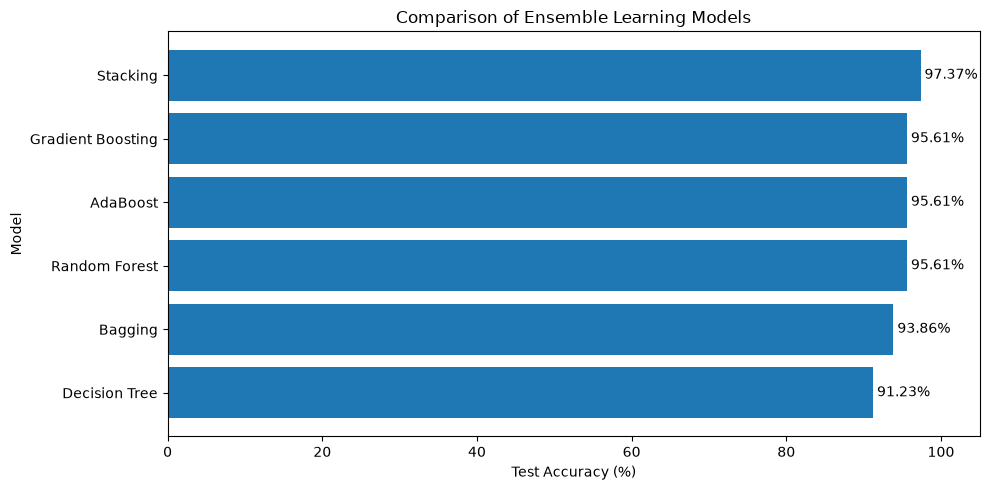

In [19]:
plot_df = results_df.sort_values("Test Accuracy")

plt.figure(figsize=(10, 5))

plt.barh(
    plot_df["Model"],
    plot_df["Test Accuracy"] * 100
)

plt.xlabel("Test Accuracy (%)")
plt.ylabel("Model")
plt.title("Comparison of Ensemble Learning Models")
plt.xlim(0, 105)

for i, value in enumerate(plot_df["Test Accuracy"]):
    plt.text(
        value * 100 + 0.5,
        i,
        f"{value * 100:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

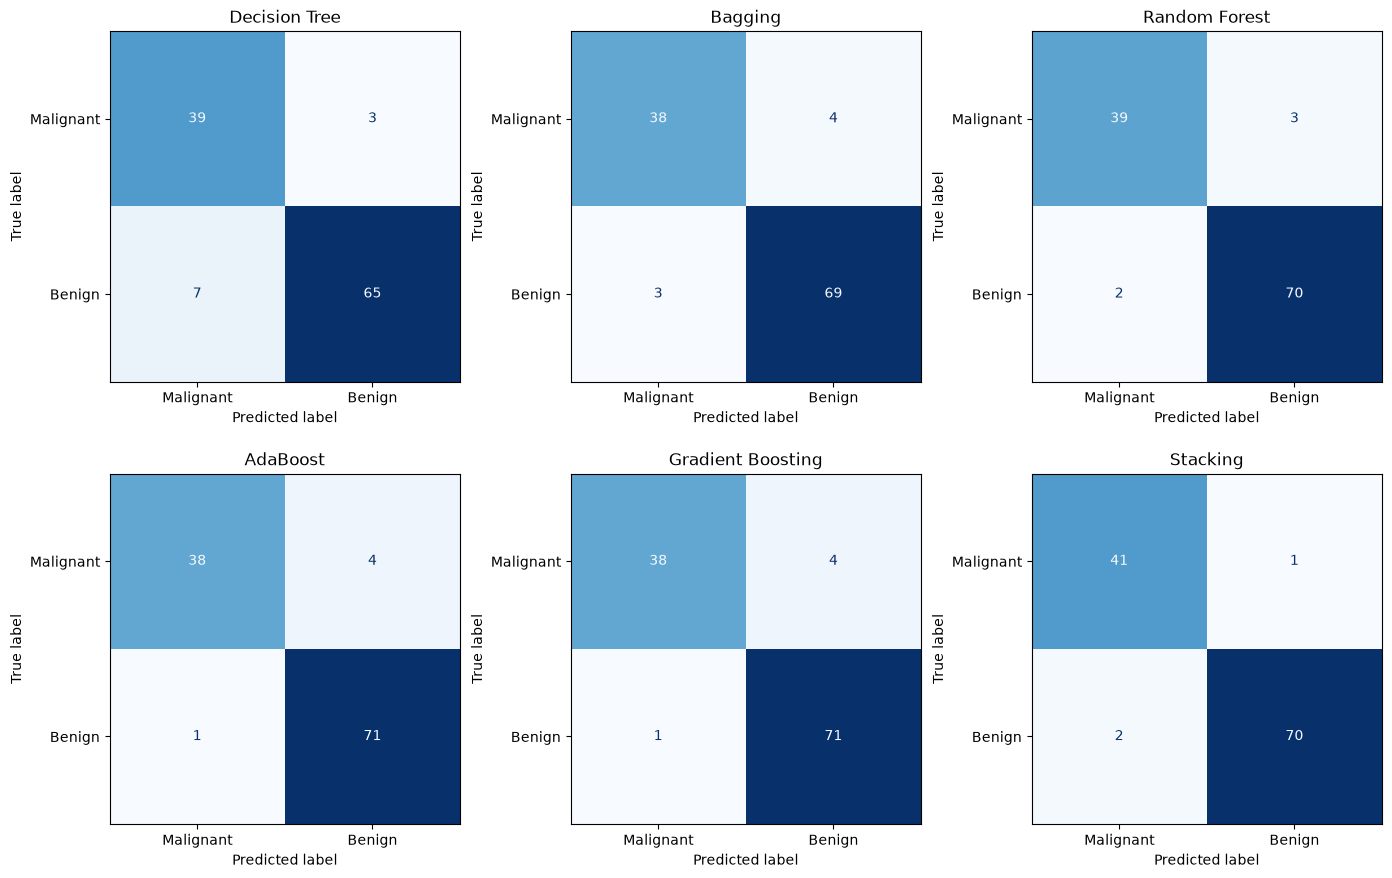

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, (name, model) in zip(axes.flat, models.items()):
    pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )

    disp.plot(
        ax=ax,
        colorbar=False,
        cmap="Blues"
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [21]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "CV Mean Accuracy": scores.mean(),
        "CV Std": scores.std()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.round(4))

print("\nOOB Evaluation")
print(f"Bagging OOB Score: {bagging_model.oob_score_:.4f}")
print(f"Random Forest OOB Score: {rf_model.oob_score_:.4f}")

,Model,CV Mean Accuracy,CV Std
0,Decision Tree,0.9165,0.0179
1,Bagging,0.9516,0.0192
2,Random Forest,0.9626,0.0179
3,AdaBoost,0.9736,0.0164
4,Gradient Boosting,0.9516,0.0149
5,Stacking,0.9736,0.0192



OOB Evaluation
Bagging OOB Score: 0.9560
Random Forest OOB Score: 0.9538


In [22]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

best_pred = best_model.predict(X_test)

print("测试准确率最高的模型：", best_model_name)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_pred,
        target_names=["Malignant", "Benign"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, best_pred))

测试准确率最高的模型： Stacking

Classification Report:
              precision    recall  f1-score   support

   Malignant     0.9535    0.9762    0.9647        42
      Benign     0.9859    0.9722    0.9790        72

    accuracy                         0.9737       114
   macro avg     0.9697    0.9742    0.9719       114
weighted avg     0.9740    0.9737    0.9737       114


Confusion Matrix:
[[41  1]
 [ 2 70]]


## 十、实验总结

### 10.1 数据集与实验设置

本实验使用 Breast Cancer Wisconsin 数据集，共包含 569 个样本、30 个数值特征，其中恶性样本 212 个，良性样本 357 个。

实验采用分层随机划分，将 80% 的样本作为训练集，20% 作为测试集，并设置 `random_state=42` 保证结果可复现。

### 10.2 单个模型与集成模型的比较

本实验以单棵决策树作为基准模型，分别训练 Bagging、Random Forest、AdaBoost、Gradient Boosting 和 Stacking，并使用相同的测试集进行评价。

各模型测试准确率如下：

| 模型 | 测试准确率 |
|---|---:|
| Decision Tree | 91.23% |
| Bagging | 93.86% |
| Random Forest | 95.61% |
| AdaBoost | 95.61% |
| Gradient Boosting | 95.61% |
| Stacking | 97.37% |

实验结果显示，五种集成学习模型的测试准确率均高于单棵决策树，说明集成方法在本次实验中改善了模型的分类性能。

其中 Stacking 的测试准确率最高，达到 **97.37%**，相比单棵决策树提高约 **6.14 个百分点**。

### 10.3 Bagging 与 Boosting 的区别

Bagging 通过 Bootstrap 有放回采样构建多个训练集，分别训练基学习器，再通过投票或平均组合预测结果，主要用于降低模型方差。

随机森林在 Bagging 决策树的基础上引入随机特征选择，增强不同决策树之间的多样性。

Boosting 采用顺序训练策略，使后续学习器不断改进已有模型的预测。其中：

- AdaBoost 通过调整样本权重，使后续模型更关注难分类样本。
- Gradient Boosting 通过拟合损失函数的负梯度（伪残差），逐步改善预测结果。

本次实验中，随机森林、AdaBoost 和 Gradient Boosting 的测试准确率均为 95.61%，未表现出明显差距。

### 10.4 OOB 与交叉验证分析

本实验使用五折交叉验证对六种模型进行补充评价。

其中，AdaBoost 和 Stacking 的平均准确率并列最高，均为 **97.36%**。

AdaBoost 的交叉验证标准差为 0.0164，Stacking 为 0.0192，说明本次交叉验证中 AdaBoost 的准确率波动略小。

此外，Bagging 的 OOB Score 为 95.60%，Random Forest 为 95.38%。

OOB 评估利用 Bootstrap 过程中未被对应基学习器采到的样本估计泛化能力，不需要额外划分专门的 OOB 验证集。

### 10.5 恶性样本识别能力分析

考虑到本实验属于医学分类任务，除了整体准确率，还需要重点关注恶性样本的 Recall。

Stacking 的恶性样本 Recall 为 **97.62%**，是六种模型中最高的。

在测试集的 42 个恶性样本中，Stacking 正确识别了 41 个，仅有 1 个恶性样本被错误分类为良性。

这说明 Stacking 在本次实验中不仅整体分类准确率较高，对恶性样本也具有较好的识别能力。

但本实验仅使用一个公开数据集，结果不能直接代表模型在真实临床环境中的诊断性能。

### 10.6 实验结论

通过本次实验，可以得出以下结论：

1. 集成学习通过组合多个基学习器，有可能提升单个模型的分类性能与泛化能力。
2. 本次实验中，Bagging、Random Forest、AdaBoost、Gradient Boosting 和 Stacking 的测试准确率均优于单棵决策树。
3. Stacking 取得最高测试准确率 97.37%，同时在恶性样本 Recall 指标上表现最好。
4. AdaBoost 和 Stacking 的五折交叉验证平均准确率均达到 97.36%，说明两者在本次实验中都具有较好的分类性能。
5. 集成学习并不保证在所有数据集上都优于单个模型，实际效果与数据分布、基学习器差异和超参数设置等因素有关。

本次实验加深了对 Bagging、Boosting、随机森林和 Stacking 等集成学习方法的理解，也掌握了使用 Scikit-learn 训练和评价多种集成模型的基本流程。